# Micro Project 4 — AE-FAR: Time-Series Anomaly Detection with MSE Feedback (Reproduction + Honest Evaluation)

**Paper.** I. Delibasoglu, F. Heintz, *Time Series Anomaly Detection Leveraging MSE Feedback with AutoEncoder and RNN*, TIME 2024, LIPIcs vol. 318, 17:1–17:12. doi:10.4230/LIPIcs.TIME.2024.17
**Official code.** https://github.com/mribrahim/AE-FAR (pinned to commit `794bb0b`; cloned at run time, not copied).
**Course.** CS/IT 433 — Topics in Deep Learning, Autumn 2026–27.

### Experiments
| ID | What | Why |
|---|---|---|
| **E0** | Evaluate the authors' **pretrained** AE-FAR models with their exact protocol | Check that our pipeline reproduces paper Table 3 |
| **E1** | **Retrain** AE and AE-FAR ourselves, 3 seeds, with a **leak-free validation set** (last 20% of training data; the official code validates on the test set) | Results without test-set selection |
| **E2** | **AE vs AE-FAR** with the same threshold rule | Does the MSE-feedback module itself help? (paper Table 1) |
| **E3** | F1 **with and without point-adjustment**, fixed vs dynamic threshold, AUC-ROC / AUC-PR | How much of the F1 comes from point-adjustment? |
| **E4** | **β sensitivity** of the dynamic threshold | How much do the results depend on β? |
| **E5** | **Random scores** + the same evaluation | Sanity check of the protocol |
| bonus | **VAE-FAR** on MSL, 1 seed (skipped automatically if time runs out) | The paper's second variant |

Datasets: **MSL** (NASA Mars rover, 55 channels) and **SMD** (server machines, 38 channels). SWaT is not used (it requires official access from iTrust).

### How to run on the laptop
- Use the Jupyter kernel with CUDA PyTorch and run all cells. The notebook stops immediately if the RTX 4060 is not available.
- MSL and SMD train one after another on the single GPU (MSL first).
- If a run is interrupted, run all cells again: seeds that already have saved scores in `aefar_work/runs` are skipped.
- Evaluation only: set `RUN_TRAINING = False`.
- Training logs: `aefar_work/runs/MSL_stdout.log` and `SMD_stdout.log`.


In [1]:
import time
NOTEBOOK_START = time.time()

import os, sys, platform, shutil, subprocess, json
import torch

print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"GPU {i}: {p.name} | {p.total_memory / 1024**3:.2f} GB")
print("CPU cores:", os.cpu_count())
total, used, free = shutil.disk_usage("/kaggle/working" if os.path.exists("/kaggle/working") else ".")
print(f"Disk free (working dir): {free / 1024**3:.1f} GB")

Python Version: 3.14.6
PyTorch Version: 2.13.0+cu130
CUDA Available: True
Number of GPUs: 1
GPU 0: NVIDIA GeForce RTX 4060 Laptop GPU | 8.00 GB
CPU cores: 24
Disk free (working dir): 162.0 GB


In [2]:
import urllib.request, urllib.error

def internet_ok(url="https://huggingface.co", timeout=10):
    try:
        urllib.request.urlopen(url, timeout=timeout); return True
    except urllib.error.HTTPError:
        return True          # the server answered
    except Exception as e:
        print("Internet check failed:", repr(e)); return False

INTERNET = internet_ok()
print("Internet:", "✓ available" if INTERNET else "✗ NOT available — connect the laptop to the internet")

Internet: ✓ available


## 1. Configuration
All settings in one cell. Model and training values follow paper §4.2 and the official code.

In [3]:
from pathlib import Path

# ---------------- run mode ----------------
DRY_RUN      = False   # True = tiny CPU smoke test on synthetic data
RUN_TRAINING = True
RESUME_FROM  = None    # not needed on the laptop: finished seeds in aefar_work/runs are skipped automatically

# ---------------- paths ----------------
ON_KAGGLE = Path("/kaggle/working").exists()
WORK      = Path("/kaggle/working") if ON_KAGGLE else Path("./aefar_work").resolve()
REPO_DIR  = WORK / "AE-FAR"            # official repo
DATA_DIR  = WORK / "Anomaly"           # official read_data() expects ../Anomaly/<DS>/ relative to the repo
OURS_DIR  = WORK / "ours"
RUNS_DIR  = WORK / "runs"
EXPORT    = WORK / "export"
FIG_DIR   = EXPORT / "figures"
REPO_URL, REPO_COMMIT = "https://github.com/mribrahim/AE-FAR", "794bb0b"
HF_REPO   = "lalababa/Time-Series-Library"   # CC BY 4.0 mirror of the standard preprocessed benchmarks
LOCAL_DATA_DIR = None                        # alternative: a Kaggle input folder with MSL/ and SMD/ files

# ---------------- experiments ----------------
DATASETS = ["MSL", "SMD"]
SEEDS    = [0, 1, 2]
RUN_VAE_ON = "MSL"          # bonus VAE-FAR (1 seed); None to disable
GPU_OF   = {"MSL": 0, "SMD": 0}   # one RTX 4060: the datasets train one after another

# ---------------- model / training (paper §4.2, official code) ----------------
WINDOW, BATCH_SIZE, LR, MAX_EPOCHS, PATIENCE = 50, 128, 1e-4, 100, 10
VAL_FRAC = 0.2              # CHANGED: leak-free validation = last 20% of the training series

# ---------------- evaluation ----------------
BETA            = {"MSL": 6.5, "SMD": 5.0}   # official code (reproduces the published numbers)
BETA_PAPER_TEXT = {"MSL": 6.5, "SMD": 4.0}   # paper §4.2 text (SMD differs from the code)
FIXED_QUANTILE  = 0.99      # leak-free fixed threshold = 99th percentile of validation scores
BETA_SWEEP      = [1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8]
N_RANDOM        = 5         # random-score baseline repeats

# ---------------- time limit for the whole notebook (hours) ----------------
SESSION_LIMIT_H, EVAL_RESERVE_H, SAFETY_H = 12.0, 1.0, 0.25

MAX_ROWS = 0
if DRY_RUN:
    SEEDS, MAX_EPOCHS, PATIENCE, MAX_ROWS, N_RANDOM = [0], 3, 2, 0, 2
    BETA_SWEEP = [2, 4, 6]

for d in [WORK, DATA_DIR, OURS_DIR, RUNS_DIR, EXPORT, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print("Working dir:", WORK)
print(f"Datasets {DATASETS} | seeds {SEEDS} | VAE-FAR bonus on {RUN_VAE_ON}")
print(f"window {WINDOW} | batch {BATCH_SIZE} | lr {LR} | max epochs {MAX_EPOCHS} | patience {PATIENCE} | val frac {VAL_FRAC}")
print("DRY_RUN:", DRY_RUN, "| RUN_TRAINING:", RUN_TRAINING, "| RESUME_FROM:", RESUME_FROM)

Working dir: D:\python\deep learning\p4\aefar_work
Datasets ['MSL', 'SMD'] | seeds [0, 1, 2] | VAE-FAR bonus on MSL
window 50 | batch 128 | lr 0.0001 | max epochs 100 | patience 10 | val frac 0.2
DRY_RUN: False | RUN_TRAINING: True | RESUME_FROM: None


In [4]:
import random
import numpy as np
random.seed(0); np.random.seed(0); torch.manual_seed(0)
DEVICE = torch.device("cuda:0" if (torch.cuda.is_available() and not DRY_RUN) else "cpu")
if not DRY_RUN:
    assert torch.cuda.is_available(), "CUDA is not available: select the kernel with CUDA PyTorch."
    GPU_NAME = torch.cuda.get_device_name(0)
    assert "4060" in GPU_NAME, f"Expected the RTX 4060 but found: {GPU_NAME}"
    print("Training GPU:", GPU_NAME)
print("Evaluation device:", DEVICE)

Training GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Evaluation device: cuda:0


## 2. Official code + our files
Clone the official repository at a fixed commit (it supplies `read_data`, the base networks, the pretrained weights, point-adjustment and the dynamic threshold). Then write our two files: `aefar_lib.py` (our implementation of the composite model, paper Eq. 1–4, and the leak-free training loop) and `run_experiment.py`.

In [5]:
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-q", REPO_COMMIT], check=True)
head = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Official repo:", REPO_DIR, "| commit", head)
for p in [str(REPO_DIR), str(OURS_DIR)]:
    if p not in sys.path: sys.path.insert(0, p)
os.chdir(OURS_DIR)
print("✓ ready")

Official repo: D:\python\deep learning\p4\aefar_work\AE-FAR | commit 794bb0b
✓ ready


In [6]:
%%writefile aefar_lib.py
"""aefar_lib.py -- Project 4 (AE-FAR reproduction) helper library.

Our own implementation of the AE-FAR composite model (paper Eq. 1-4) and of the leak-free
training / scoring pipeline. Class and attribute names of AttentionLayer, MSEFeedbackRNN and
CompositeModel deliberately match the official notebooks (github.com/mribrahim/AE-FAR, commit
794bb0b) so that the authors' pickled pretrained models can be loaded and checked (experiment E0).

The base networks (CustomModel = the "AE", LSTM_VAE) and the evaluation helpers
(read_data, apply_adjustment, sliding_window_anomaly_detection) are imported from the official
repository at run time; this file does not copy them.
"""
import json, os, random, time

import numpy as np
import torch
import torch.nn as nn


# ----------------------------------------------------------------------------------------------
# Composite model (paper Eq. 2-4). Same structure and names as the official notebooks.
# ----------------------------------------------------------------------------------------------
class AttentionLayer(nn.Module):
    """alpha = Softmax(Linear(tanh(Linear(z)))), z' = alpha * z   (paper Eq. 2)."""

    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, 1), nn.Softmax(dim=1))

    def forward(self, inputs):
        attention_weights = self.attention(inputs)
        return inputs * attention_weights, attention_weights


class MSEFeedbackRNN(nn.Module):
    """h = FC(RNN(z')) (paper Eq. 3). As in the official code, the RNN receives a sequence of
    length 1 with a zero initial state, so it carries no memory across time steps."""

    def __init__(self, input_size, hidden_size, output_size, num_layers=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = x.unsqueeze(1)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)
        out, _ = self.rnn(x, h0)
        return self.fc(out)


class CompositeModel(nn.Module):
    """y_hat = X_hat + RNN(alpha * [X_hat, MSE])   (paper Eq. 4)."""

    def __init__(self, autoencoder, rnn, attention_dim=64, input_dim=None):
        super().__init__()
        self.autoencoder = autoencoder
        self.rnn = rnn
        self.attention = AttentionLayer(input_dim=input_dim + 1, hidden_dim=attention_dim)

    def forward(self, x, y):
        out = self.autoencoder(x)
        reconstructed = out[0] if isinstance(out, tuple) else out       # VAE returns a tuple
        mse_error = ((y - reconstructed) ** 2).mean(dim=1, keepdim=True)  # uses the true y
        combined_input = torch.cat((reconstructed, mse_error), dim=1)
        combined_input, _ = self.attention(combined_input)
        rnn_output = self.rnn(combined_input).squeeze(1)
        return reconstructed + rnn_output, mse_error, rnn_output


def vae_loss(recon_x, x, mu, log_var, window_size, input_dim):
    """Official VAE loss (train-model.ipynb): reconstruction of the LAST point of the window
    (sum-reduced MSE) + 0.002 * KL divergence."""
    x_data = x[:, window_size - 1, :]
    rec = nn.functional.mse_loss(recon_x, x_data.view(-1, input_dim), reduction="sum")
    kl = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return rec + 0.002 * kl


# ----------------------------------------------------------------------------------------------
# Windowing: identical batches to the official iterate_batches (window -> next point,
# consecutive, no shuffling), but built with one vectorised gather instead of a Python loop.
# ----------------------------------------------------------------------------------------------
def iterate_batches_fast(data, window_size, batch_size, start_idx=0):
    n = len(data) - window_size
    offs = torch.arange(window_size, device=data.device)
    for start in range(start_idx, n, batch_size):
        end = min(start + batch_size, n)
        idx = torch.arange(start, end, device=data.device)
        yield data[idx[:, None] + offs], data[idx + window_size]


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ----------------------------------------------------------------------------------------------
# Training (official loop: Adam lr 1e-4, batch 128, max 100 epochs, early stop when the
# validation loss has not improved for more than 10 epochs) -- with a leak-free validation set.
# ----------------------------------------------------------------------------------------------
def _step_loss(model, kind, xb, yb, window_size, input_dim, loss_fn):
    if kind == "composite":
        y_pred, _, _ = model(xb, yb)
        return loss_fn(y_pred, yb)
    if kind == "ae":
        return loss_fn(model(xb), yb)
    y_pred, mu, log_var = model(xb)                     # vae
    return vae_loss(y_pred, xb, mu, log_var, window_size, input_dim)


def train_model(model, kind, X_train, X_val, cfg, log_path, deadline=0.0):
    """Returns (model with best weights, info dict). kind in {'ae', 'vae', 'composite'}."""
    loss_fn = nn.MSELoss()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=cfg["lr"])
    w, bs, d = cfg["window"], cfg["batch_size"], X_train.shape[1]
    best, best_state, stop_counter, rows = np.inf, None, 0, []
    status, t0 = "completed", time.time()
    for epoch in range(cfg["max_epochs"]):
        if deadline and time.time() > deadline:
            status = "stopped_at_deadline"; break
        te = time.time()
        model.train()
        tr = []
        for xb, yb in iterate_batches_fast(X_train, w, bs):
            opt.zero_grad()
            loss = _step_loss(model, kind, xb, yb, w, d, loss_fn)
            loss.backward(); opt.step(); tr.append(loss.item())
        model.eval()
        with torch.no_grad():
            va = [_step_loss(model, kind, xb, yb, w, d, loss_fn).item()
                  for xb, yb in iterate_batches_fast(X_val, w, bs)]
        tr_m, va_m = float(np.mean(tr)), float(np.mean(va))
        rows.append({"epoch": epoch, "train_loss": tr_m, "val_loss": va_m, "epoch_s": round(time.time() - te, 3)})
        if va_m < best:
            best, stop_counter = va_m, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stop_counter += 1
        if stop_counter > cfg["patience"]:
            status = "early_stopped"; break
    if best_state is not None:
        model.load_state_dict(best_state)
    with open(log_path, "w") as f:
        json.dump(rows, f)
    info = {"kind": kind, "status": status, "epochs_run": len(rows), "best_val_loss": best,
            "best_epoch": int(np.argmin([r["val_loss"] for r in rows])) if rows else None,
            "train_s": round(time.time() - t0, 1),
            "mean_epoch_s": float(np.mean([r["epoch_s"] for r in rows])) if rows else None}
    return model, info


@torch.no_grad()
def score(model, kind, X, window_size, batch_size):
    """Per-time-step anomaly score = mean squared error over features between the true value
    and the model output (official test-model.ipynb). Returns array of length len(X)-window."""
    model.eval()
    preds = []
    for xb, yb in iterate_batches_fast(X, window_size, batch_size):
        if kind == "composite":
            p = model(xb, yb)[0]
        elif kind == "ae":
            p = model(xb)
        else:
            p = model(xb)[0]
        preds.append(p.float().cpu())
    preds = torch.cat(preds).numpy()
    truth = X[window_size:].float().cpu().numpy()
    return np.mean((truth - preds) ** 2, axis=1)

Overwriting aefar_lib.py


In [7]:
%%writefile run_experiment.py
"""run_experiment.py -- trains AE and AE-FAR (and optionally VAE / VAE-FAR) for one dataset and
several seeds, leak-free, and saves the anomaly scores for evaluation.

Per seed:  stage 1 = train the base network (AE or VAE) alone;  stage 2 = freeze it and train the
attention + MSE-feedback RNN (AE-FAR / VAE-FAR), exactly as the official two-phase procedure.
CHANGED vs. official: validation = last VAL_FRAC of the training series (official: the test set).
"""
import argparse, json, os, sys, time

import numpy as np
import torch


def main(a):
    os.chdir(a.repo)                                  # official read_data uses ../Anomaly/<DS>/
    sys.path.insert(0, a.repo); sys.path.insert(0, a.lib_dir)
    from utils import read_data                       # official
    from my_models import CustomModel, LSTM_VAE       # official
    import aefar_lib as L

    dev = torch.device(a.device)
    train_np, test_np, _val_official, labels = read_data(a.dataset)   # scaler fit on train only
    labels = np.asarray(labels).reshape(-1).astype(int)
    if a.max_rows:                                    # DRY_RUN only
        train_np, test_np, labels = train_np[:a.max_rows], test_np[:a.max_rows], labels[:a.max_rows]
    n_val = int(len(train_np) * a.val_frac)
    X_tr = torch.tensor(train_np[:-n_val], dtype=torch.float32, device=dev)
    X_va = torch.tensor(train_np[-n_val:], dtype=torch.float32, device=dev)
    X_te = torch.tensor(test_np, dtype=torch.float32, device=dev)
    d = X_tr.shape[1]
    cfg = dict(window=a.window, batch_size=a.batch_size, lr=a.lr, max_epochs=a.max_epochs, patience=a.patience)
    print(f"[{a.dataset}] train {tuple(X_tr.shape)} val {tuple(X_va.shape)} test {tuple(X_te.shape)} "
          f"anomaly rate {labels.mean():.4f} device {dev}", flush=True)

    # all AE seeds first; the VAE (bonus) runs last, first seed only, if time remains
    jobs = [("ae", s) for s in a.seeds] + ([("vae", a.seeds[0])] if a.vae else [])
    for base, seed in jobs:
        if True:
            out = os.path.join(a.out, a.dataset, f"{base}_seed{seed}")
            os.makedirs(out, exist_ok=True)
            if os.path.exists(os.path.join(out, "scores.npz")):
                print(f"[{a.dataset}] {base} seed {seed}: already done, skipping", flush=True)
                continue
            if a.deadline and time.time() > a.deadline:
                print(f"[{a.dataset}] {base} seed {seed}: SKIPPED (session deadline)", flush=True)
                json.dump({"status": "skipped_deadline"}, open(os.path.join(out, "info.json"), "w"))
                continue
            L.set_seed(seed)
            # ---- stage 1: base network ----
            base_net = (CustomModel(a.window, d) if base == "ae"
                        else LSTM_VAE(a.window, input_size=d, hidden_size=64, latent_size=32)).to(dev)
            base_net, info1 = L.train_model(base_net, base, X_tr, X_va, cfg,
                                            os.path.join(out, "log_stage1.json"), a.deadline)
            torch.save(base_net.state_dict(), os.path.join(out, "base.pt"))
            print(f"[{a.dataset}] {base} seed {seed} stage1 {info1}", flush=True)
            # ---- stage 2: composite (frozen base + attention + MSE-feedback RNN) ----
            for p in base_net.parameters():
                p.requires_grad = False
            rnn = L.MSEFeedbackRNN(input_size=d + 1, hidden_size=d // 2, output_size=d, num_layers=8)
            comp = L.CompositeModel(base_net, rnn, attention_dim=64, input_dim=d).to(dev)
            comp, info2 = L.train_model(comp, "composite", X_tr, X_va, cfg,
                                        os.path.join(out, "log_stage2.json"), a.deadline)
            torch.save(comp.state_dict(), os.path.join(out, "composite.pt"))
            print(f"[{a.dataset}] {base} seed {seed} stage2 {info2}", flush=True)
            # ---- scores (val scores are used for the leak-free fixed threshold) ----
            np.savez_compressed(
                os.path.join(out, "scores.npz"),
                base_test=L.score(base_net, base, X_te, a.window, a.batch_size),
                far_test=L.score(comp, "composite", X_te, a.window, a.batch_size),
                base_val=L.score(base_net, base, X_va, a.window, a.batch_size),
                far_val=L.score(comp, "composite", X_va, a.window, a.batch_size),
                labels=labels[a.window:])
            json.dump({"dataset": a.dataset, "base": base, "seed": seed, "n_features": d,
                       "stage1": info1, "stage2": info2,
                       "device": torch.cuda.get_device_name(0) if dev.type == "cuda" else "cpu",
                       "peak_vram_gb": round(torch.cuda.max_memory_allocated() / 1024**3, 3) if dev.type == "cuda" else None},
                      open(os.path.join(out, "info.json"), "w"), indent=2)
    print(f"[{a.dataset}] DONE", flush=True)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True)
    ap.add_argument("--repo", required=True)
    ap.add_argument("--lib_dir", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--seeds", type=int, nargs="+", default=[0, 1, 2])
    ap.add_argument("--vae", action="store_true")
    ap.add_argument("--window", type=int, default=50)
    ap.add_argument("--batch_size", type=int, default=128)
    ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--max_epochs", type=int, default=100)
    ap.add_argument("--patience", type=int, default=10)
    ap.add_argument("--val_frac", type=float, default=0.2)
    ap.add_argument("--deadline", type=float, default=0)
    ap.add_argument("--max_rows", type=int, default=0)
    ap.add_argument("--device", default="cuda")
    main(ap.parse_args())

Overwriting run_experiment.py


In [8]:
import importlib
import aefar_lib as L; importlib.reload(L)
from aefar_lib import AttentionLayer, MSEFeedbackRNN, CompositeModel   # names needed to unpickle the official models
from utils import read_data, apply_adjustment, sliding_window_anomaly_detection   # official
from my_models import CustomModel, LSTM_VAE                                         # official
print("✓ imports OK")

✓ imports OK


## 3. Data — MSL and SMD
The standard preprocessed benchmark files (the same files used by Anomaly Transformer, DCdetector and the official AE-FAR code), downloaded from a CC BY 4.0 Hugging Face mirror into the folder layout that the official `read_data()` expects.

In [9]:
FILES = {"MSL": ["MSL_train.npy", "MSL_test.npy", "MSL_test_label.npy"],
         "SMD": ["SMD_train.npy", "SMD_test.npy", "SMD_test_label.npy"]}
N_FEAT = {"MSL": 55, "SMD": 38}

def have(ds): return all((DATA_DIR / ds / f).exists() for f in FILES[ds])

for ds in DATASETS:
    (DATA_DIR / ds).mkdir(parents=True, exist_ok=True)
    if have(ds):
        print(ds, "already present"); continue
    if DRY_RUN:
        rng = np.random.default_rng(0); n, d = 1500, N_FEAT[ds]; t = np.arange(n)[:, None]
        tr = np.sin(t / 20 + np.arange(d)) + 0.1 * rng.normal(size=(n, d))
        te = np.sin(t / 20 + np.arange(d)) + 0.1 * rng.normal(size=(n, d)); lab = np.zeros(n)
        for s in [300, 800, 1200]: te[s:s + 30] += 3; lab[s:s + 30] = 1
        np.save(DATA_DIR / ds / FILES[ds][0], tr); np.save(DATA_DIR / ds / FILES[ds][1], te)
        np.save(DATA_DIR / ds / FILES[ds][2], lab); print(ds, "DRY_RUN synthetic data"); continue
    if LOCAL_DATA_DIR:
        for f in FILES[ds]:
            src = next(Path(LOCAL_DATA_DIR).rglob(f)); shutil.copy(src, DATA_DIR / ds / f)
        continue
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=False)
    from huggingface_hub import hf_hub_download
    for f in FILES[ds]:
        p = hf_hub_download(repo_id=HF_REPO, repo_type="dataset", filename=f"{ds}/{f}")
        shutil.copy(p, DATA_DIR / ds / f)
    print(ds, "downloaded")

DATA_INFO = {}
os.chdir(REPO_DIR)        # read_data uses ../Anomaly/<DS>/
for ds in DATASETS:
    tr, te, _, lab = read_data(ds)
    lab = np.asarray(lab).reshape(-1).astype(int)
    segs = int(((lab[1:] == 1) & (lab[:-1] == 0)).sum() + lab[0])
    DATA_INFO[ds] = {"train_rows": len(tr), "test_rows": len(te), "features": tr.shape[1],
                     "test_anomaly_rate": round(float(lab.mean()), 4), "anomaly_segments": segs}
    print(ds, DATA_INFO[ds])
os.chdir(OURS_DIR)

MSL already present
SMD already present
MSL {'train_rows': 58317, 'test_rows': 73729, 'features': 55, 'test_anomaly_rate': 0.1053, 'anomaly_segments': 36}


SMD {'train_rows': 708405, 'test_rows': 708420, 'features': 38, 'test_anomaly_rate': 0.0416, 'anomaly_segments': 327}


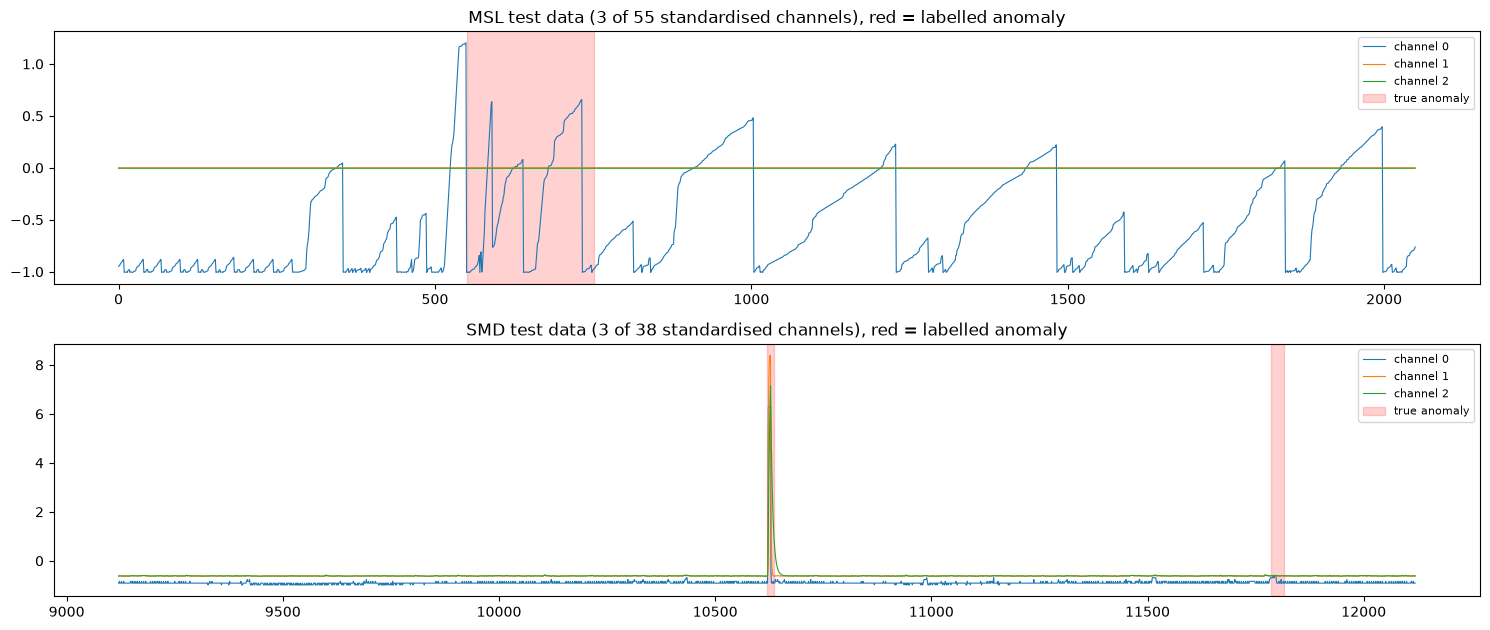

In [10]:
import matplotlib
import matplotlib.pyplot as plt

def shade(ax, lab, x0=0, color="red", alpha=0.18, label="true anomaly"):
    on = False
    for i, v in enumerate(lab):
        if v and not on: s, on = i, True
        if not v and on: ax.axvspan(x0 + s, x0 + i, color=color, alpha=alpha, label=label); label = None; on = False
    if on: ax.axvspan(x0 + s, x0 + len(lab), color=color, alpha=alpha, label=label)

os.chdir(REPO_DIR)
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(15, 3.2 * len(DATASETS)))
axes = np.atleast_1d(axes)
for ax, ds in zip(axes, DATASETS):
    _, te, _, lab = read_data(ds); lab = np.asarray(lab).reshape(-1)
    first = int(np.argmax(lab > 0)); a, b = max(0, first - 1500), min(len(lab), first + 1500)
    for k in range(3): ax.plot(np.arange(a, b), te[a:b, k], lw=0.8, label=f"channel {k}")
    shade(ax, lab[a:b], x0=a)
    ax.set_title(f"{ds} test data (3 of {te.shape[1]} standardised channels), red = labelled anomaly"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "data_examples.png", dpi=140); plt.show()
os.chdir(OURS_DIR)

## 4. Evaluation helpers
- **Point-adjustment (PA)**: the official `apply_adjustment` — if any point of a true anomaly segment is detected, the whole segment counts as detected (paper §4.1).
- **Dynamic threshold**: the official `sliding_window_anomaly_detection` — T[t] = moving mean + β × moving std of the score over a window of 50 (paper §3.3, Eq. 5–6).
- **Fixed threshold (leak-free)**: 99th percentile of the validation scores. (The paper does not state how its fixed threshold was chosen.)

In [11]:
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, average_precision_score

def prf(gt, pred):
    p, r, f, _ = precision_recall_fscore_support(gt, pred, average="binary", zero_division=0)
    return float(p), float(r), float(f)

BEST_Q = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]   # flag-rate grid for the oracle threshold

def evaluate(score_test, labels, beta, fixed_thr=None, best=False):
    out = {}
    dyn, _ = sliding_window_anomaly_detection(score_test, WINDOW, threshold_factor=beta)
    dyn = np.asarray(dyn)
    preds = {"dynamic": dyn}
    if fixed_thr is not None:
        preds["fixed"] = (score_test > fixed_thr).astype(int)
    for crit, pred in preds.items():
        out[f"{crit}_noPA"] = prf(labels, pred)
        _, pa = apply_adjustment(labels, pred)
        out[f"{crit}_PA"] = prf(labels, pa)
        out[f"{crit}_flag_rate"] = float(pred.mean())
    if best:   # oracle: best threshold chosen ON THE TEST LABELS (the optimistic protocol used by many papers)
        for tag, use_pa in [("best_noPA", False), ("best_PA", True)]:
            cands = []
            for q in BEST_Q:
                pred = (score_test > np.quantile(score_test, 1 - q)).astype(int)
                if use_pa: _, pred = apply_adjustment(labels, pred)
                cands.append(prf(labels, pred))
            out[tag] = max(cands, key=lambda t: t[2])
        out["best_flag_rate"] = float("nan")
    out["auc_roc"] = float(roc_auc_score(labels, score_test))
    out["auc_pr"] = float(average_precision_score(labels, score_test))
    return out
print("✓ helpers ready")

✓ helpers ready


## 5. E0 — Verify the authors' pretrained models
Load the official pickled AE-FAR models (`models/<DS>/<DS>-AE-FAR.pt`), score the test set and apply the official criterion and point-adjustment. If our pipeline matches theirs, this reproduces **paper Table 3** (AE-FAR: MSL F1 93.85, SMD F1 90.06).

In [12]:
PAPER = {   # [PAPER] Table 3 (AE-FAR, VAE-FAR, baselines) and Table 1 (ablation), all with point-adjustment
    "table3": {"MSL": {"AE-FAR": (92.59, 95.13, 93.85), "VAE-FAR": (90.23, 94.89, 92.50),
                       "AnomalyTransformer": (92.09, 95.15, 93.59), "DCdetector": (93.69, 99.69, 96.60),
                       "OmniAnomaly": (89.02, 86.37, 87.67)},
               "SMD": {"AE-FAR": (92.01, 88.20, 90.06), "VAE-FAR": (89.95, 94.59, 92.21),
                       "AnomalyTransformer": (89.40, 95.45, 92.33), "DCdetector": (83.59, 91.10, 87.18),
                       "OmniAnomaly": (83.68, 86.82, 85.22)}},
    "table1": {"MSL": {"AE": (95.70, 20.91, 34.32), "AE-FAR": (83.57, 90.45, 86.87), "VAE-FAR": (52.87, 96.87, 68.41),
                       "AE*": (85.23, 99.54, 91.83), "AE-FAR*": (92.59, 95.13, 93.85), "VAE-FAR*": (90.23, 94.89, 92.50)},
               "SMD": {"AE": (38.10, 68.09, 48.86), "AE-FAR": (62.72, 52.01, 56.86), "VAE-FAR": (81.28, 76.81, 78.98),
                       "AE*": (91.89, 87.78, 89.79), "AE-FAR*": (92.01, 88.20, 90.06), "VAE-FAR*": (89.95, 94.59, 92.21)}},
}

E0 = {}
os.chdir(REPO_DIR)
for ds in DATASETS:
    _, te, _, lab = read_data(ds); lab = np.asarray(lab).reshape(-1).astype(int)
    model = torch.load(REPO_DIR / "models" / ds / f"{ds}-AE-FAR.pt", map_location=DEVICE, weights_only=False).to(DEVICE)
    X = torch.tensor(te, dtype=torch.float32, device=DEVICE)
    s = L.score(model, "composite", X, WINDOW, BATCH_SIZE)
    E0[ds] = evaluate(s, lab[WINDOW:], BETA[ds])
    E0[ds]["paper_text_beta"] = evaluate(s, lab[WINDOW:], BETA_PAPER_TEXT[ds])["dynamic_PA"]
    p, r, f = E0[ds]["dynamic_PA"]
    print(f"{ds}: pretrained AE-FAR, β={BETA[ds]}, PA → P {100*p:.2f}  R {100*r:.2f}  F1 {100*f:.2f}   "
          f"| paper Table 3: {PAPER['table3'][ds]['AE-FAR']}")
    print(f"     without PA → F1 {100*E0[ds]['dynamic_noPA'][2]:.2f} | AUC-ROC {E0[ds]['auc_roc']:.3f} | AUC-PR {E0[ds]['auc_pr']:.3f}"
          f" | with paper-text β={BETA_PAPER_TEXT[ds]}: PA F1 {100*E0[ds]['paper_text_beta'][2]:.2f}")
    del model; torch.cuda.empty_cache()
os.chdir(OURS_DIR)

MSL: pretrained AE-FAR, β=6.5, PA → P 92.59  R 95.13  F1 93.85   | paper Table 3: (92.59, 95.13, 93.85)
     without PA → F1 1.78 | AUC-ROC 0.631 | AUC-PR 0.152 | with paper-text β=6.5: PA F1 93.85


SMD: pretrained AE-FAR, β=5.0, PA → P 83.82  R 96.03  F1 89.51   | paper Table 3: (92.01, 88.2, 90.06)
     without PA → F1 3.77 | AUC-ROC 0.759 | AUC-PR 0.167 | with paper-text β=4.0: PA F1 85.97


## 6. Model check
Parameter counts of the base AE, the official LSTM-VAE and the composite (attention + 8-layer RNN) for each dataset.

In [13]:
PARAMS = {}
for ds in DATASETS:
    d = N_FEAT[ds]
    ae = CustomModel(WINDOW, d)
    comp = CompositeModel(ae, MSEFeedbackRNN(d + 1, d // 2, d, num_layers=8), 64, input_dim=d)
    vae = LSTM_VAE(WINDOW, input_size=d, hidden_size=64, latent_size=32)
    cnt = lambda m: sum(p.numel() for p in m.parameters())
    PARAMS[ds] = {"AE": cnt(ae), "FAR_module (attention+RNN)": cnt(comp) - cnt(ae), "AE-FAR total": cnt(comp), "LSTM-VAE": cnt(vae)}
    x = torch.randn(2, WINDOW, d); y = torch.randn(2, d)
    assert comp(x, y)[0].shape == (2, d)
    print(ds, PARAMS[ds])
print("✓ Model check passed")

MSL {'AE': 90919, 'FAR_module (attention+RNN)': 18132, 'AE-FAR total': 109051, 'LSTM-VAE': 130308}
SMD {'AE': 63158, 'FAR_module (attention+RNN)': 9845, 'AE-FAR total': 73003, 'LSTM-VAE': 108174}
✓ Model check passed


## 7. Training (E1) — MSL, then SMD, on the RTX 4060
Per seed: stage 1 trains the AE alone; stage 2 freezes it and trains the attention + MSE-feedback RNN (official two-phase procedure). Validation = last 20% of the training series. The VAE-FAR bonus runs last on MSL, only if time remains.

In [14]:
if RESUME_FROM:
    src = next(Path(RESUME_FROM).rglob("runs"), None)
    if src is None: raise RuntimeError(f"No runs/ folder under {RESUME_FROM}")
    shutil.copytree(src, RUNS_DIR, dirs_exist_ok=True); print("Restored runs from", src)

TRAIN_DEADLINE = NOTEBOOK_START + (SESSION_LIMIT_H - EVAL_RESERVE_H - SAFETY_H) * 3600
N_GPUS = 0 if DRY_RUN else torch.cuda.device_count()

def launch(ds, gpu):
    cmd = [sys.executable, str(OURS_DIR / "run_experiment.py"), "--dataset", ds, "--repo", str(REPO_DIR),
           "--lib_dir", str(OURS_DIR), "--out", str(RUNS_DIR), "--seeds", *map(str, SEEDS),
           "--window", str(WINDOW), "--batch_size", str(BATCH_SIZE), "--lr", str(LR),
           "--max_epochs", str(MAX_EPOCHS), "--patience", str(PATIENCE), "--val_frac", str(VAL_FRAC),
           "--deadline", str(0 if DRY_RUN else TRAIN_DEADLINE), "--max_rows", str(MAX_ROWS)]
    if RUN_VAE_ON == ds: cmd.append("--vae")
    env = dict(os.environ)
    if DRY_RUN or gpu is None:
        cmd += ["--device", "cpu"]; env["CUDA_VISIBLE_DEVICES"] = ""
    else:
        env["CUDA_VISIBLE_DEVICES"] = str(gpu)
    log = RUNS_DIR / f"{ds}_stdout.log"
    return subprocess.Popen(cmd, env=env, stdout=open(log, "w"), stderr=subprocess.STDOUT), log

def wait(procs):
    last = time.time()
    while any(p.poll() is None for p, _ in procs.values()):
        time.sleep(2 if DRY_RUN else 15)
        if time.time() - last > 120:
            for ds, (_, log) in procs.items():
                lines = [l for l in open(log).read().splitlines() if l.startswith(f"[{ds}]")]
                print(lines[-1][:220] if lines else f"[{ds}] (starting)")
            last = time.time()
    for ds, (p, log) in procs.items():
        if p.returncode != 0:
            print(open(log).read()[-3000:]); raise RuntimeError(f"{ds} failed")

if RUN_TRAINING:
    t0 = time.time()
    if N_GPUS >= 2 or DRY_RUN:
        procs = {ds: launch(ds, None if DRY_RUN else GPU_OF[ds]) for ds in DATASETS}
        wait(procs)
    else:   # one GPU: run the datasets one after another
        for ds in DATASETS:
            wait({ds: launch(ds, 0 if N_GPUS else None)})
    print(f"Training finished in {(time.time() - t0) / 3600:.2f} h")

for ds in DATASETS:
    print("\n" + "\n".join(l for l in open(RUNS_DIR / f"{ds}_stdout.log").read().splitlines() if "stage" in l or "SKIPPED" in l or "DONE" in l))

[MSL] ae seed 0 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 20, 'best_val_loss': 0.526463643619586, 'best_epoch': 8, 'train_s': 11.6, 'mean_epoch_s': 0.57765}


[MSL] ae seed 1 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 28, 'best_val_loss': 0.5319048099963066, 'best_epoch': 16, 'train_s': 20.2, 'mean_epoch_s': 0.7212142857142858}


[MSL] ae seed 1 stage2 {'kind': 'composite', 'status': 'completed', 'epochs_run': 100, 'best_val_loss': 0.40502454636837254, 'best_epoch': 99, 'train_s': 163.3, 'mean_epoch_s': 1.6316799999999996}


[MSL] ae seed 2 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 21, 'best_val_loss': 0.529116360622888, 'best_epoch': 9, 'train_s': 16.2, 'mean_epoch_s': 0.7719047619047618}


[MSL] ae seed 2 stage2 {'kind': 'composite', 'status': 'completed', 'epochs_run': 100, 'best_val_loss': 0.40789734708672326, 'best_epoch': 99, 'train_s': 173.9, 'mean_epoch_s': 1.73774}


[MSL] ae seed 2 stage2 {'kind': 'composite', 'status': 'completed', 'epochs_run': 100, 'best_val_loss': 0.40789734708672326, 'best_epoch': 99, 'train_s': 173.9, 'mean_epoch_s': 1.73774}


... (83 outputs left out)

[SMD] ae seed 2 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 45, 'best_val_loss': 0.30517714892622577, 'best_epoch': 33, 'train_s': 581.2, 'mean_epoch_s': 12.915022222222222}


[SMD] ae seed 2 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 45, 'best_val_loss': 0.30517714892622577, 'best_epoch': 33, 'train_s': 581.2, 'mean_epoch_s': 12.915022222222222}


[SMD] ae seed 2 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 45, 'best_val_loss': 0.30517714892622577, 'best_epoch': 33, 'train_s': 581.2, 'mean_epoch_s': 12.915022222222222}


Training finished in 3.11 h

[MSL] ae seed 1 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 28, 'best_val_loss': 0.5319048099963066, 'best_epoch': 16, 'train_s': 20.2, 'mean_epoch_s': 0.7212142857142858}
[MSL] ae seed 1 stage2 {'kind': 'composite', 'status': 'completed', 'epochs_run': 100, 'best_val_loss': 0.40502454636837254, 'best_epoch': 99, 'train_s': 163.0, 'mean_epoch_s': 1.6286500000000002}
[MSL] ae seed 2 stage1 {'kind': 'ae', 'status': 'early_stopped', 'epochs_run': 21, 'best_val_loss': 0.529116360622888, 'best_epoch': 9, 'train_s': 15.4, 'mean_epoch_s': 0.7327619047619048}
[MSL] ae seed 2 stage2 {'kind': 'composite', 'status': 'completed', 'epochs_run': 100, 'best_val_loss': 0.40789734708672326, 'best_epoch': 99, 'train_s': 176.1, 'mean_epoch_s': 1.76012}
[MSL] vae seed 0 stage1 {'kind': 'vae', 'status': 'completed', 'epochs_run': 100, 'best_val_loss': 963.8907517443646, 'best_epoch': 99, 'train_s': 3836.8, 'mean_epoch_s': 38.367689999999996}
[MSL] vae seed 0 

## 8. Training curves

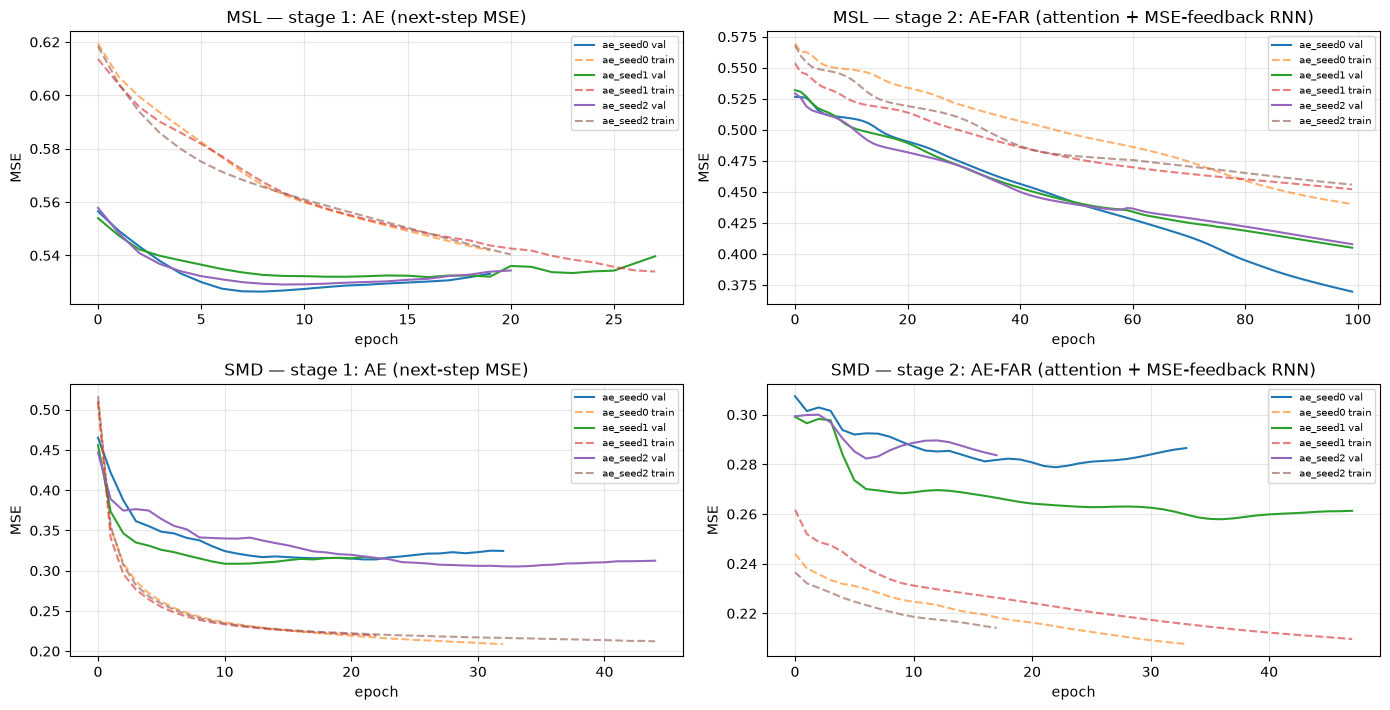

In [15]:
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 3.6 * len(DATASETS)))
axes = np.atleast_2d(axes)
for i, ds in enumerate(DATASETS):
    for run in sorted((RUNS_DIR / ds).glob("ae_seed*")):
        for j, stage in enumerate(["log_stage1.json", "log_stage2.json"]):
            if not (run / stage).exists(): continue
            rows = json.load(open(run / stage))
            axes[i, j].plot([r["val_loss"] for r in rows], label=f"{run.name} val")
            axes[i, j].plot([r["train_loss"] for r in rows], "--", alpha=.6, label=f"{run.name} train")
    axes[i, 0].set_title(f"{ds} — stage 1: AE (next-step MSE)"); axes[i, 1].set_title(f"{ds} — stage 2: AE-FAR (attention + MSE-feedback RNN)")
    for a in axes[i]: a.set_xlabel("epoch"); a.set_ylabel("MSE"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "training_curves.png", dpi=140); plt.show()

## 9. E2–E5 — Evaluation
For every dataset, seed and model: dynamic (paper) and fixed (leak-free) thresholds, each **with and without point-adjustment**, plus threshold-free AUC-ROC / AUC-PR. Random scores go through exactly the same evaluation. We also report a **best-threshold (oracle)** F1, where the threshold is picked using the test labels — an optimistic protocol, shown only to illustrate how much point-adjustment can flatter even random scores.

In [16]:
import pandas as pd
ROWS, SCORES = [], {}
EVALS = ["dynamic_noPA", "dynamic_PA", "fixed_noPA", "fixed_PA", "best_noPA", "best_PA"]
for ds in DATASETS:
    for run in sorted((RUNS_DIR / ds).glob("*_seed*")):
        if not (run / "scores.npz").exists():
            print("missing scores:", run); continue
        z = np.load(run / "scores.npz"); base, seed = run.name.split("_seed"); seed = int(seed)
        lab = z["labels"].astype(int)
        names = {"ae": ("AE", "AE-FAR"), "vae": ("VAE", "VAE-FAR")}[base]
        for name, key in zip(names, ["base", "far"]):
            thr = float(np.quantile(z[f"{key}_val"], FIXED_QUANTILE))
            r = evaluate(z[f"{key}_test"], lab, BETA[ds], fixed_thr=thr, best=True)
            SCORES[(ds, name, seed)] = (z[f"{key}_test"], lab)
            for k in EVALS:
                ROWS.append({"dataset": ds, "model": name, "seed": seed, "eval": k,
                             "P": r[k][0], "R": r[k][1], "F1": r[k][2],
                             "flag_rate": r[k.split("_")[0] + "_flag_rate"], "auc_roc": r["auc_roc"], "auc_pr": r["auc_pr"]})
    # E5: random scores
    lab = next(v[1] for k, v in SCORES.items() if k[0] == ds)
    for s in range(N_RANDOM):
        rnd = np.random.default_rng(1000 + s).random(len(lab))
        r = evaluate(rnd, lab, BETA[ds], fixed_thr=float(np.quantile(rnd, FIXED_QUANTILE)), best=True)
        for k in EVALS:
            ROWS.append({"dataset": ds, "model": "Random", "seed": s, "eval": k, "P": r[k][0], "R": r[k][1], "F1": r[k][2],
                         "flag_rate": r[k.split("_")[0] + "_flag_rate"], "auc_roc": r["auc_roc"], "auc_pr": r["auc_pr"]})

df = pd.DataFrame(ROWS); df.to_csv(EXPORT / "metrics_per_seed.csv", index=False)
summ = (df.groupby(["dataset", "model", "eval"])[["P", "R", "F1", "flag_rate", "auc_roc", "auc_pr"]]
          .agg(["mean", "std"]).round(4))
summ.to_csv(EXPORT / "metrics_summary.csv")
order = ["Random", "AE", "AE-FAR", "VAE", "VAE-FAR"]
for ds in DATASETS:
    print(f"\n===== {ds} (β = {BETA[ds]}, mean over seeds, %) =====")
    t = df[df.dataset == ds].groupby(["model", "eval"])["F1"].mean().unstack().mul(100).round(2)
    t = t.reindex([m for m in order if m in t.index])[EVALS[::-1]]
    a = df[df.dataset == ds].groupby("model")[["auc_roc", "auc_pr"]].mean().round(3)
    print(t.join(a))


===== MSL (β = 6.5, mean over seeds, %) =====
         best_PA  best_noPA  fixed_PA  fixed_noPA  dynamic_PA  dynamic_noPA  \
model                                                                         
Random     90.72      17.49     89.41        1.84        0.00          0.00   
AE         86.43      23.36     88.48        6.55       91.53          1.41   
AE-FAR     87.03      23.96     88.54        6.55       91.76          1.67   
VAE        85.70      19.71     86.39        6.55       89.90          0.98   
VAE-FAR    85.65      19.80     86.50        6.54       91.84          1.30   

         auc_roc  auc_pr  
model                     
Random     0.502   0.106  
AE         0.617   0.147  
AE-FAR     0.627   0.151  
VAE        0.549   0.138  
VAE-FAR    0.550   0.140  

===== SMD (β = 5.0, mean over seeds, %) =====
        best_PA  best_noPA  fixed_PA  fixed_noPA  dynamic_PA  dynamic_noPA  \
model                                                                        
Random 

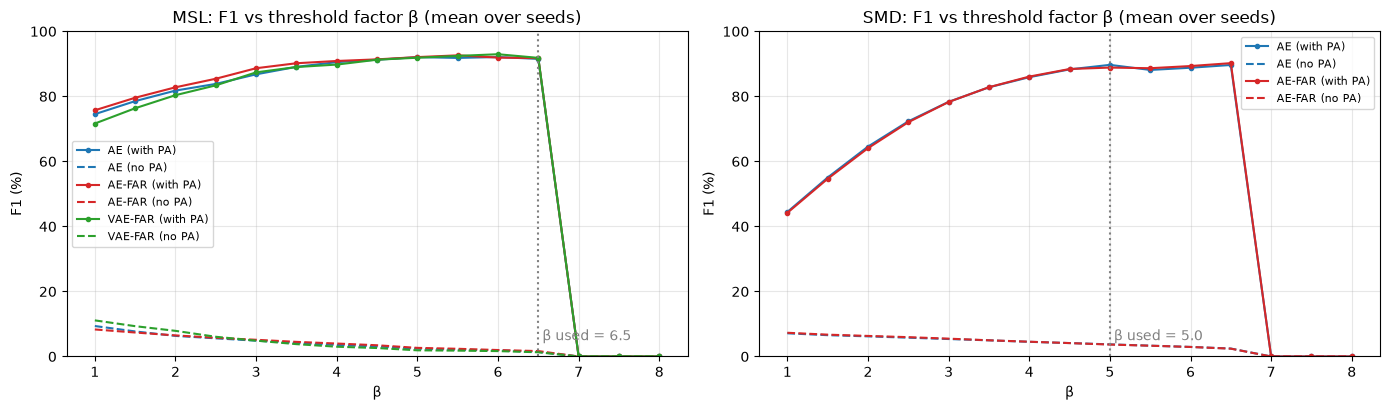

In [17]:
# E4: β sensitivity (mean over seeds)
SWEEP = []
for (ds, name, seed), (s, lab) in SCORES.items():
    for b in BETA_SWEEP:
        r = evaluate(s, lab, b)
        SWEEP.append({"dataset": ds, "model": name, "seed": seed, "beta": b,
                      "F1_PA": r["dynamic_PA"][2], "F1_noPA": r["dynamic_noPA"][2]})
sw = pd.DataFrame(SWEEP); sw.to_csv(EXPORT / "beta_sweep.csv", index=False)

fig, axes = plt.subplots(1, len(DATASETS), figsize=(7 * len(DATASETS), 4.2))
axes = np.atleast_1d(axes)
for ax, ds in zip(axes, DATASETS):
    for name, c in [("AE", "#1f77b4"), ("AE-FAR", "#d62728"), ("VAE-FAR", "#2ca02c")]:
        m = sw[(sw.dataset == ds) & (sw.model == name)].groupby("beta")[["F1_PA", "F1_noPA"]].mean()
        if m.empty: continue
        ax.plot(m.index, 100 * m.F1_PA, "-o", color=c, ms=3, label=f"{name} (with PA)")
        ax.plot(m.index, 100 * m.F1_noPA, "--", color=c, label=f"{name} (no PA)")
    ax.axvline(BETA[ds], color="gray", ls=":"); ax.text(BETA[ds] + 0.05, 5, f"β used = {BETA[ds]}", color="gray")
    ax.set_title(f"{ds}: F1 vs threshold factor β (mean over seeds)"); ax.set_xlabel("β"); ax.set_ylabel("F1 (%)")
    ax.set_ylim(0, 100); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "beta_sensitivity.png", dpi=140); plt.show()

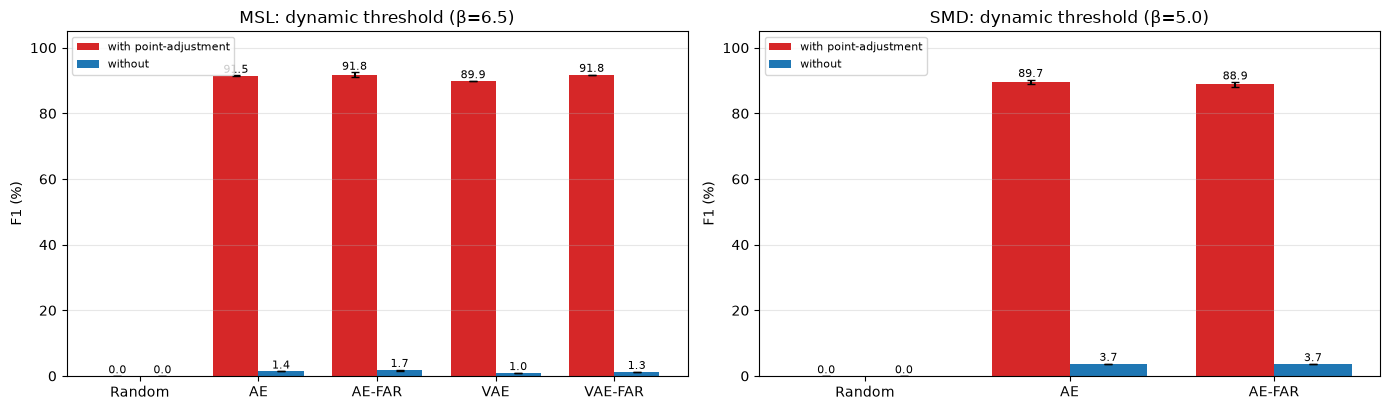

In [18]:
# F1 with vs without point-adjustment (dynamic threshold), mean ± std over seeds
fig, axes = plt.subplots(1, len(DATASETS), figsize=(7 * len(DATASETS), 4.2))
axes = np.atleast_1d(axes)
for ax, ds in zip(axes, DATASETS):
    sub = df[(df.dataset == ds) & (df["eval"].isin(["dynamic_PA", "dynamic_noPA"]))]
    models = [m for m in order if m in sub.model.unique()]
    x = np.arange(len(models)); w = 0.38
    for k, (ev, col, lbl) in enumerate([("dynamic_PA", "#d62728", "with point-adjustment"), ("dynamic_noPA", "#1f77b4", "without")]):
        g = sub[sub["eval"] == ev].groupby("model")["F1"]
        mu, sd = g.mean().reindex(models), g.std().reindex(models).fillna(0)
        bars = ax.bar(x + (k - 0.5) * w, 100 * mu, w, yerr=100 * sd, capsize=3, color=col, label=lbl)
        ax.bar_label(bars, fmt="%.1f", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(models); ax.set_ylim(0, 105); ax.set_ylabel("F1 (%)")
    ax.set_title(f"{ds}: dynamic threshold (β={BETA[ds]})"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "f1_pa_vs_nopa.png", dpi=140); plt.show()

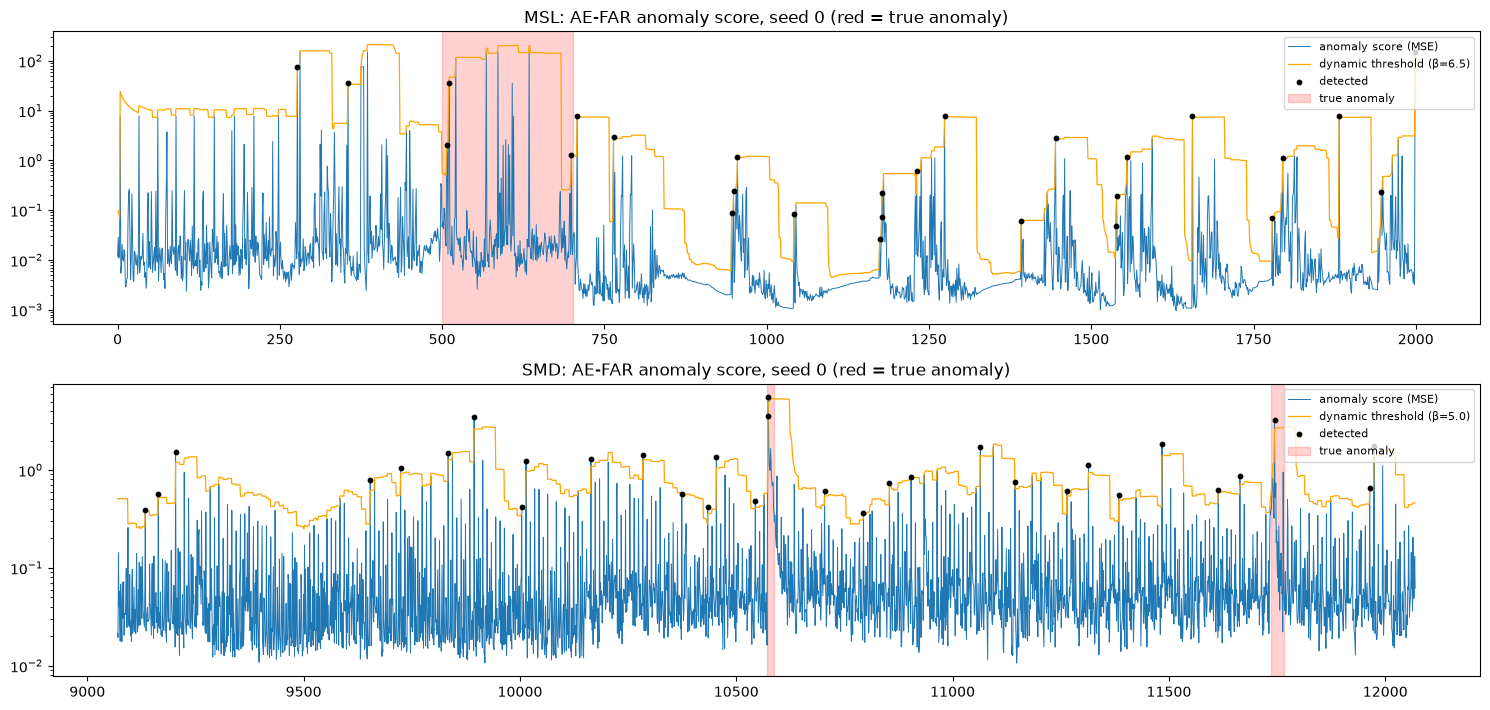

In [19]:
# Anomaly score over time with the dynamic threshold (AE-FAR, first seed)
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(15, 3.6 * len(DATASETS)))
axes = np.atleast_1d(axes)
for ax, ds in zip(axes, DATASETS):
    s, lab = SCORES[(ds, "AE-FAR", SEEDS[0])]
    pred, thr = sliding_window_anomaly_detection(s, WINDOW, threshold_factor=BETA[ds])
    pred, thr = np.asarray(pred), np.asarray(thr)
    first = int(np.argmax(lab > 0)); a, b = max(0, first - 1500), min(len(lab), first + 1500)
    xs = np.arange(a, b)
    ax.plot(xs, s[a:b], lw=0.7, color="#1f77b4", label="anomaly score (MSE)")
    ax.plot(xs, thr[a:b], lw=0.9, color="orange", label=f"dynamic threshold (β={BETA[ds]})")
    hit = xs[pred[a:b] == 1]; ax.scatter(hit, s[hit], s=10, color="black", zorder=3, label="detected")
    shade(ax, lab[a:b], x0=a); ax.set_yscale("log")
    ax.set_title(f"{ds}: AE-FAR anomaly score, seed {SEEDS[0]} (red = true anomaly)"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "anomaly_score_timeline.png", dpi=140); plt.show()

## 10. Results summary and export

In [20]:
infos = {str(p.relative_to(RUNS_DIR)): json.load(open(p)) for p in RUNS_DIR.rglob("info.json")}
def mean_std(ds, model, ev, col="F1"):
    g = df[(df.dataset == ds) & (df.model == model) & (df["eval"] == ev)][col]
    return (float(g.mean()), float(g.std(ddof=1)) if len(g) > 1 else 0.0, int(len(g)))

results = {
    "environment": {"python": platform.python_version(), "torch": torch.__version__,
                    "gpus": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
                    "official_commit": head, "dry_run": DRY_RUN},
    "config": {"datasets": DATASETS, "seeds": SEEDS, "window": WINDOW, "batch_size": BATCH_SIZE, "lr": LR,
               "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "val_frac": VAL_FRAC, "beta": BETA,
               "beta_paper_text": BETA_PAPER_TEXT, "fixed_quantile": FIXED_QUANTILE, "n_random": N_RANDOM},
    "data": DATA_INFO, "params": PARAMS,
    "E0_pretrained": E0,
    "runs": infos,
    "summary_F1": {ds: {m: {ev: mean_std(ds, m, ev) for ev in EVALS}
                        for m in df[df.dataset == ds].model.unique()} for ds in DATASETS},
    "summary_auc": {ds: {m: {"auc_roc": mean_std(ds, m, "dynamic_PA", "auc_roc"), "auc_pr": mean_std(ds, m, "dynamic_PA", "auc_pr")}
                         for m in df[df.dataset == ds].model.unique()} for ds in DATASETS},
    "paper_reference": PAPER,
}
json.dump(results, open(EXPORT / "results.json", "w"), indent=2, default=float)

print("=" * 80); print("MEASURED (this notebook) — F1 %, mean ± std over seeds"); print("=" * 80)
for ds in DATASETS:
    print(f"\n{ds}:  E0 pretrained AE-FAR (PA) F1 = {100 * E0[ds]['dynamic_PA'][2]:.2f}   [paper Table 3: {PAPER['table3'][ds]['AE-FAR'][2]}]")
    for m in [m for m in order if m in df[df.dataset == ds].model.unique()]:
        a, b = results["summary_F1"][ds][m]["dynamic_PA"], results["summary_F1"][ds][m]["dynamic_noPA"]
        print(f"  {m:8s} dynamic+PA {100*a[0]:6.2f} ± {100*a[1]:5.2f}   dynamic, no PA {100*b[0]:6.2f} ± {100*b[1]:5.2f}   (n={a[2]})")
print("\nNot directly comparable with the paper: leak-free validation (paper code validates on test), several seeds "
      f"(paper: one run), {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'} (paper: RTX 3060). Point-adjusted F1 is the paper's protocol; F1 without PA is the strict one.")

MEASURED (this notebook) — F1 %, mean ± std over seeds

MSL:  E0 pretrained AE-FAR (PA) F1 = 93.85   [paper Table 3: 93.85]
  Random   dynamic+PA   0.00 ±  0.00   dynamic, no PA   0.00 ±  0.00   (n=5)
  AE       dynamic+PA  91.53 ±  0.03   dynamic, no PA   1.41 ±  0.03   (n=3)
  AE-FAR   dynamic+PA  91.76 ±  0.72   dynamic, no PA   1.67 ±  0.26   (n=3)
  VAE      dynamic+PA  89.90 ±  0.00   dynamic, no PA   0.98 ±  0.00   (n=1)
  VAE-FAR  dynamic+PA  91.84 ±  0.00   dynamic, no PA   1.30 ±  0.00   (n=1)

SMD:  E0 pretrained AE-FAR (PA) F1 = 89.51   [paper Table 3: 90.06]
  Random   dynamic+PA   0.00 ±  0.00   dynamic, no PA   0.00 ±  0.00   (n=5)
  AE       dynamic+PA  89.69 ±  0.59   dynamic, no PA   3.73 ±  0.05   (n=3)
  AE-FAR   dynamic+PA  88.86 ±  0.68   dynamic, no PA   3.67 ±  0.01   (n=3)

Not directly comparable with the paper: leak-free validation (paper code validates on test), several seeds (paper: one run), NVIDIA GeForce RTX 4060 Laptop GPU (paper: RTX 3060). Point-adjus

In [21]:
for f in RUNS_DIR.glob("*_stdout.log"): shutil.copy(f, EXPORT / f.name)
for p in RUNS_DIR.rglob("*.json"):
    dst = EXPORT / "runs" / p.relative_to(RUNS_DIR); dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy(p, dst)
for f in ["aefar_lib.py", "run_experiment.py"]: shutil.copy(OURS_DIR / f, EXPORT / f)
zip_path = shutil.make_archive(str(WORK / "aefar_p4_export"), "zip", EXPORT)
print("Export folder:", EXPORT)
for p in sorted(EXPORT.rglob("*")):
    if p.is_file() and "runs" not in p.parts: print(f"  {p.relative_to(EXPORT)}  ({p.stat().st_size / 1024:.0f} KB)")
print("\n✓ Zip for the slides:", zip_path)
print(f"Total notebook time: {(time.time() - NOTEBOOK_START) / 3600:.2f} h")

Export folder: D:\python\deep learning\p4\aefar_work\export
  aefar_lib.py  (8 KB)
  beta_sweep.csv  (10 KB)
  figures\anomaly_score_timeline.png  (460 KB)
  figures\beta_sensitivity.png  (110 KB)
  figures\data_examples.png  (140 KB)
  figures\f1_pa_vs_nopa.png  (48 KB)
  figures\training_curves.png  (270 KB)
  metrics_per_seed.csv  (18 KB)
  metrics_summary.csv  (4 KB)
  MSL_stdout.log  (2 KB)
  results.json  (17 KB)
  run_experiment.py  (6 KB)
  SMD_stdout.log  (1 KB)

✓ Zip for the slides: D:\python\deep learning\p4\aefar_work\aefar_p4_export.zip
Total notebook time: 3.16 h
